In [1]:
import sys, os
print(sys.executable)
print(os.getcwd())

/home/tharunn/Desktop/voltrelay-hackathon/.venv/bin/python
/home/tharunn/Desktop/voltrelay-hackathon


In [10]:
import duckdb
from pathlib import Path
from voltrelay_hackathon.profiling import profile_table
from voltrelay_hackathon.cleaning import normalize_city, flag_impossible_battery_values

con = duckdb.connect()
DATA = Path("data")

TABLES = ["batteries","stations","riders","support_tickets",
          "city_daily_context","fleet_partners","swap_events","station_hourly_status"]

SWAP_EVENTS_SCHEMA = {
    "event_id": "VARCHAR",
    "rider_id": "VARCHAR",
    "station_id": "VARCHAR",
    "event_ts": "TIMESTAMP",
    "event_type": "VARCHAR",
    "attempt_seq": "INTEGER",
    "queue_wait_sec": "INTEGER",
    "battery_in_id": "VARCHAR",
    "battery_out_id": "VARCHAR",
    "soc_in_pct": "DOUBLE",
    "soh_in_pct": "DOUBLE",
    "soc_out_pct": "DOUBLE",
    "soh_out_pct": "DOUBLE",
    "km_since_last_swap": "DOUBLE",
    "tariff_code": "VARCHAR",
    "list_price_inr": "DOUBLE",
    "discount_inr": "DOUBLE",
    "amount_charged_inr": "DOUBLE",
    "payment_mode": "VARCHAR",
    "energy_to_recharge_kwh": "DOUBLE",
    "station_firmware": "VARCHAR",
    "sync_mode": "VARCHAR",
}

for t in TABLES:
    if t == "swap_events":
        con.execute(f"""
            CREATE OR REPLACE VIEW {t} AS
            SELECT * FROM read_csv(
                '{DATA/t}.csv',
                header = true,
                delim = ',',
                quote = '"',
                escape = '"',
                columns = {SWAP_EVENTS_SCHEMA},
                auto_detect = false,
                ignore_errors = true,
                strict_mode = false,
                max_line_size = 10000000
            )
        """)
    else:
        con.execute(f"CREATE OR REPLACE VIEW {t} AS SELECT * FROM read_csv_auto('{DATA/t}.csv')")

profile_table(con, "riders", pk_cols=["rider_id"])
profile_table(con, "stations", pk_cols=["station_id"])
profile_table(con, "batteries", pk_cols=["battery_id"])
profile_table(con, "swap_events", pk_cols=["event_id"])
profile_table(con, "station_hourly_status", pk_cols=["station_id", "hour_start"])
profile_table(con, "support_tickets", pk_cols=["ticket_id"])
profile_table(con, "city_daily_context", pk_cols=["city", "date"])
profile_table(con, "fleet_partners", pk_cols=["partner_id"])


=== riders (20,000 rows, 12 cols) ===
                null_pct
partner_id         38.14
declared_shift     18.31
age_band            7.74
Duplicate ['rider_id']: 0

=== stations (152 rows, 22 cols) ===
                               null_pct
decommissioned_date               99.34
competitor_within_1_5km_since     93.42
Duplicate ['station_id']: 0

=== batteries (6,500 rows, 13 cols) ===
                   null_pct
retired_date          77.88
retirement_reason     77.88
Duplicate ['battery_id']: 0

=== swap_events (3,877,013 rows, 22 cols) ===
                        null_pct
battery_in_id               0.73
battery_out_id              5.96
soc_in_pct                  0.73
soh_in_pct                  0.73
soc_out_pct                 5.96
soh_out_pct                 5.96
km_since_last_swap          0.73
energy_to_recharge_kwh      5.96
Duplicate ['event_id']: 0

=== station_hourly_status (1,487,712 rows, 14 cols) ===
                    null_pct
charged_2w_avg          0.63
charged_2w_

,column_name,column_type,null,key,default,extra
0,partner_id,VARCHAR,YES,None,None,None
1,partner_name,VARCHAR,YES,None,None,None
2,partner_segment,VARCHAR,YES,None,None,None
3,vehicle_class,VARCHAR,YES,None,None,None
4,contract_type,VARCHAR,YES,None,None,None
5,contract_start_date,DATE,YES,None,None,None
6,discount_pct,DOUBLE,YES,None,None,None
7,amendment_date,DATE,YES,None,None,None
8,discount_pct_after_amendment,DOUBLE,YES,None,None,None
9,peak_surcharge_billable,VARCHAR,YES,None,None,None


In [9]:
con.sql("SELECT count(*) FROM swap_events").df()

,count_star()
0,3877013


In [11]:
con.sql("""
SELECT event_type, count(*) n,
       round(100.0 * sum(CASE WHEN battery_out_id IS NULL THEN 1 ELSE 0 END) / count(*), 1) AS pct_null_battery_out
FROM swap_events GROUP BY event_type ORDER BY n DESC
""").df()

,event_type,n,pct_null_battery_out
0,swap_completed,3645809,0.0
1,failed_no_charged_battery,134389,100.0
2,abandoned_queue,68533,100.0
3,cancelled_by_rider,16712,100.0
4,failed_system_error,11570,100.0


In [12]:
con.sql("""
SELECT s.slots_3w = 0 AS no_3w_slots, count(*) n,
       round(100.0 * sum(CASE WHEN h.charged_3w_min IS NULL THEN 1 ELSE 0 END) / count(*), 1) AS pct_null
FROM station_hourly_status h JOIN stations s USING (station_id)
GROUP BY 1
""").df()

,no_3w_slots,n,pct_null
0,False,669552,0.5
1,True,818160,100.0


In [13]:
riders_df = con.sql("SELECT * FROM riders").df()
riders_df["home_city_clean"] = normalize_city(riders_df["home_city"])
print(riders_df["home_city_clean"].value_counts())

home_city_clean
Bengaluru    4310
Delhi NCR    3886
Hyderabad    3485
Pune         2929
Mumbai       2874
Jaipur       2516
Name: count, dtype: int64


In [14]:
con.sql("""
SELECT station_firmware,
       min(event_ts) AS min_ts,
       max(event_ts) AS max_ts,
       count(*) FILTER (WHERE date_part('second', event_ts) = 0) * 100.0 / count(*) AS pct_zero_seconds,
       mode() WITHIN GROUP (ORDER BY date_part('hour', event_ts)) AS peak_hour
FROM swap_events
GROUP BY station_firmware
""").df()

,station_firmware,min_ts,max_ts,pct_zero_seconds,peak_hour
0,v3.2.0,2024-01-01 00:09:00,2025-06-30 23:57:40,1.644083,19
1,v3.2.1,2024-01-01 00:00:33,2025-06-30 23:59:23,1.668553,19


In [15]:
con.sql("""
SELECT s.firmware_updated_date, date_trunc('day', e.event_ts) AS day, count(*)
FROM swap_events e JOIN stations s USING (station_id)
WHERE e.station_firmware = s.firmware_version
GROUP BY 1,2 ORDER BY 1,2 LIMIT 50
""").df()

,firmware_updated_date,day,count_star()
0,2025-03-10,2024-01-01,724
1,2025-03-10,2024-01-02,1345
2,2025-03-10,2024-01-03,1414
3,2025-03-10,2024-01-04,1406
4,2025-03-10,2024-01-05,1408
5,2025-03-10,2024-01-06,1531
6,2025-03-10,2024-01-07,1466
7,2025-03-10,2024-01-08,1451
8,2025-03-10,2024-01-09,1411
9,2025-03-10,2024-01-10,1410


In [16]:
con.sql("""
SELECT station_firmware,
       count(*) AS total_events,
       count(*) FILTER (WHERE date_part('minute', event_ts) = 0 AND date_part('second', event_ts) = 0) AS exact_hour_marks,
       count(DISTINCT date_trunc('hour', event_ts)) AS distinct_hours_seen,
       stddev(date_part('second', event_ts)) AS second_stddev
FROM swap_events
GROUP BY station_firmware
""").df()

,station_firmware,total_events,exact_hour_marks,distinct_hours_seen,second_stddev
0,v3.2.1,2315839,678,13128,17.317956
1,v3.2.0,1561174,424,13123,17.304114


In [17]:
con.sql("""
SELECT date_trunc('day', event_ts) AS day, station_firmware, count(*) AS n
FROM swap_events
GROUP BY 1, 2
ORDER BY day
""").df()

,day,station_firmware,n
0,2024-01-01,v3.2.0,724
1,2024-01-01,v3.2.1,1131
2,2024-01-02,v3.2.1,1958
3,2024-01-02,v3.2.0,1345
4,2024-01-03,v3.2.0,1414
...,...,...,...
1089,2025-06-28,v3.2.0,4696
1090,2025-06-29,v3.2.0,4701
1091,2025-06-29,v3.2.1,7039
1092,2025-06-30,v3.2.0,4585


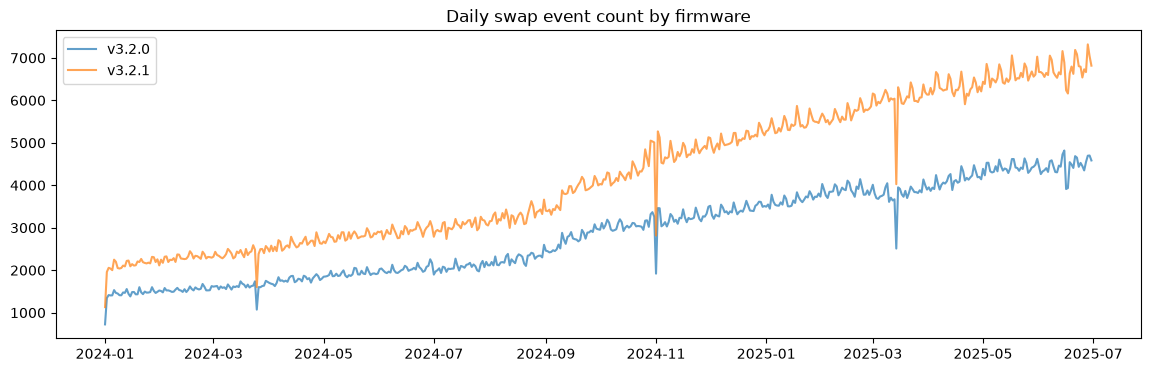

In [18]:
daily = con.sql("""
SELECT date_trunc('day', event_ts) AS day, station_firmware, count(*) AS n
FROM swap_events
GROUP BY 1, 2
ORDER BY day
""").df()

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(14,4))
for fw, g in daily.groupby("station_firmware"):
    ax.plot(g["day"], g["n"], label=fw, alpha=0.7)
ax.legend()
ax.set_title("Daily swap event count by firmware")
plt.show()


In [19]:
v320 = daily[daily["station_firmware"] == "v3.2.0"].copy()
v320["rolling_avg"] = v320["n"].rolling(7, center=True).mean()
v320["deviation"] = v320["n"] - v320["rolling_avg"]

# show the days that dropped furthest below their local trend
v320.sort_values("deviation").head(10)

,day,station_firmware,n,rolling_avg,deviation
611,2024-11-01,v3.2.0,1919,3117.285714,-1198.285714
877,2025-03-14,v3.2.0,2510,3597.857143,-1087.857143
1064,2025-06-16,v3.2.0,3912,4409.285714,-497.285714
169,2024-03-25,v3.2.0,1072,1557.285714,-485.285714
1067,2025-06-17,v3.2.0,3936,4404.857143,-468.857143
939,2025-04-14,v3.2.0,3889,4106.571429,-217.571429
830,2025-02-19,v3.2.0,3729,3930.285714,-201.285714
467,2024-08-21,v3.2.0,2101,2290.142857,-189.142857
1084,2025-06-26,v3.2.0,4350,4529.571429,-179.571429
364,2024-07-01,v3.2.0,1897,2063.285714,-166.285714


In [1]:
# replace 'YYYY-MM-DD' with whatever date the previous query shows
suspect_date = 'YYYY-MM-DD'

con.sql(f"""
SELECT date_trunc('hour', event_ts) AS hour, count(*) AS n
FROM swap_events
WHERE station_firmware = 'v3.2.0' AND date_trunc('day', event_ts) = DATE '{suspect_date}'
GROUP BY 1 ORDER BY 1
""").df()


NameError: name 'con' is not defined

In [21]:
for suspect_date in ["2024-11-01", "2025-03-14"]:
    print(f"=== {suspect_date} ===")
    result = con.sql(f"""
        SELECT date_trunc('hour', event_ts) AS hour, count(*) AS n
        FROM swap_events
        WHERE station_firmware = 'v3.2.0' AND date_trunc('day', event_ts) = DATE '{suspect_date}'
        GROUP BY 1 ORDER BY 1
    """).df()
    print(result)
    print()

=== 2024-11-01 ===
                  hour    n
0  2024-11-01 00:00:00   16
1  2024-11-01 01:00:00    6
2  2024-11-01 02:00:00    9
3  2024-11-01 03:00:00    5
4  2024-11-01 04:00:00   16
5  2024-11-01 05:00:00   10
6  2024-11-01 06:00:00   28
7  2024-11-01 07:00:00   27
8  2024-11-01 08:00:00   91
9  2024-11-01 09:00:00  126
10 2024-11-01 10:00:00   87
11 2024-11-01 11:00:00   52
12 2024-11-01 12:00:00  192
13 2024-11-01 13:00:00  178
14 2024-11-01 14:00:00   70
15 2024-11-01 15:00:00   46
16 2024-11-01 16:00:00   59
17 2024-11-01 17:00:00   81
18 2024-11-01 18:00:00  101
19 2024-11-01 19:00:00  198
20 2024-11-01 20:00:00  242
21 2024-11-01 21:00:00  169
22 2024-11-01 22:00:00   98
23 2024-11-01 23:00:00   12

=== 2025-03-14 ===
                  hour    n
0  2025-03-14 00:00:00   27
1  2025-03-14 01:00:00   44
2  2025-03-14 02:00:00   73
3  2025-03-14 03:00:00  126
4  2025-03-14 04:00:00  115
5  2025-03-14 05:00:00   67
6  2025-03-14 06:00:00  137
7  2025-03-14 07:00:00  220
8  2025-0

In [22]:
con.sql("""
SELECT station_firmware, count(*) AS n
FROM swap_events
WHERE date_trunc('day', event_ts) = DATE '2024-11-01'
GROUP BY 1
""").df()


,station_firmware,n
0,v3.2.1,2816
1,v3.2.0,1919


In [23]:
con.sql("""
SELECT * FROM city_daily_context
WHERE date = DATE '2024-11-01'
""").df()

,city,date,max_temp_c,min_temp_c,rainfall_mm,heat_alert,flood_disruption,festival_or_event,is_public_holiday,grid_outage_hours,competitor_promo_active,ecommerce_sale_event
0,Bengaluru,2024-11-01,19.0,8.0,0.0,False,False,Diwali,True,0.0,False,False
1,Delhi NCR,2024-11-01,15.4,7.8,0.0,False,False,Diwali,True,0.0,False,False
2,Hyderabad,2024-11-01,20.5,5.4,0.2,False,False,Diwali,True,0.0,False,False
3,Pune,2024-11-01,17.5,7.9,1.7,False,False,Diwali,True,0.0,False,False
4,Mumbai,2024-11-01,23.8,7.3,0.0,False,False,Diwali,True,0.1,False,False
5,Jaipur,2024-11-01,13.6,5.4,0.0,False,False,Diwali,True,0.0,False,False


In [24]:
con.sql("""
SELECT * FROM city_daily_context
WHERE date = DATE '2025-03-14'
""").df()

,city,date,max_temp_c,min_temp_c,rainfall_mm,heat_alert,flood_disruption,festival_or_event,is_public_holiday,grid_outage_hours,competitor_promo_active,ecommerce_sale_event
0,Bengaluru,2025-03-14,22.6,8.0,0.0,False,False,Holi,True,0.0,True,False
1,Delhi NCR,2025-03-14,23.1,7.4,0.2,False,False,Holi,True,0.1,False,False
2,Hyderabad,2025-03-14,25.2,10.4,0.0,False,False,Holi,True,0.0,False,False
3,Pune,2025-03-14,21.7,10.2,2.2,False,False,Holi,True,0.3,True,False
4,Mumbai,2025-03-14,27.0,13.1,0.0,False,False,Holi,True,0.2,False,False
5,Jaipur,2025-03-14,23.7,9.7,0.0,False,False,Holi,True,0.1,False,False


In [25]:
# look for impossible timestamps: swap events logged before their station existed,
# or after the dataset's stated end date, per firmware
con.sql("""
SELECT s.station_id, s.commissioned_date, min(e.event_ts) AS first_swap
FROM swap_events e JOIN stations s USING (station_id)
GROUP BY 1, 2
HAVING min(e.event_ts) < s.commissioned_date
""").df()

,station_id,commissioned_date,first_swap
0,STN-HYD-087,2025-03-15,2025-03-14 19:00:40
1,STN-HYD-088,2025-04-11,2025-04-10 19:05:31
2,STN-MUM-130,2025-04-14,2025-04-13 21:33:58
3,STN-PUN-109,2025-04-08,2025-04-07 18:52:18
4,STN-MUM-129,2025-03-26,2025-03-25 19:36:35
5,STN-MUM-128,2025-04-13,2025-04-12 20:46:21
6,STN-BLR-031,2025-03-26,2025-03-25 19:44:19


In [26]:
con.sql("""
SELECT s.station_id, s.commissioned_date, s.firmware_version,
       min(e.event_ts) AS first_swap,
       e.station_firmware,
       s.commissioned_date - min(e.event_ts)::date AS days_diff
FROM swap_events e JOIN stations s USING (station_id)
GROUP BY 1, 2, 3, 5
HAVING min(e.event_ts) < s.commissioned_date
ORDER BY days_diff DESC
""").df()

,station_id,commissioned_date,firmware_version,first_swap,station_firmware,days_diff
0,STN-HYD-087,2025-03-15,v3.2.0,2025-03-14 19:00:40,v3.2.0,1
1,STN-MUM-128,2025-04-13,v3.2.0,2025-04-12 20:46:21,v3.2.0,1
2,STN-PUN-109,2025-04-08,v3.2.0,2025-04-07 18:52:18,v3.2.0,1
3,STN-BLR-031,2025-03-26,v3.2.0,2025-03-25 19:44:19,v3.2.0,1
4,STN-HYD-088,2025-04-11,v3.2.0,2025-04-10 19:05:31,v3.2.0,1
5,STN-MUM-129,2025-03-26,v3.2.0,2025-03-25 19:36:35,v3.2.0,1
6,STN-MUM-130,2025-04-14,v3.2.0,2025-04-13 21:33:58,v3.2.0,1


In [31]:
con.sql("""
SELECT station_firmware,
       count(*) FILTER (WHERE date_part('hour', event_ts) BETWEEN 18 AND 23) * 100.0 / count(*) AS pct_evening,
       count(*) FILTER (WHERE date_part('hour', event_ts) BETWEEN 0 AND 5) * 100.0 / count(*) AS pct_early_morning
FROM swap_events
GROUP BY station_firmware
""").df()

,station_firmware,pct_evening,pct_early_morning
0,v3.2.1,44.698271,3.620545
1,v3.2.0,41.000234,4.915532


In [13]:
import duckdb
from pathlib import Path
from voltrelay_hackathon.profiling import profile_table
from voltrelay_hackathon.cleaning import normalize_city, flag_impossible_battery_values

con = duckdb.connect()
DATA = Path("data")

TABLES = ["batteries","stations","riders","support_tickets",
          "city_daily_context","fleet_partners","swap_events","station_hourly_status"]

SWAP_EVENTS_SCHEMA = {
    "event_id": "VARCHAR", "rider_id": "VARCHAR", "station_id": "VARCHAR",
    "event_ts": "TIMESTAMP", "event_type": "VARCHAR", "attempt_seq": "INTEGER",
    "queue_wait_sec": "INTEGER", "battery_in_id": "VARCHAR", "battery_out_id": "VARCHAR",
    "soc_in_pct": "DOUBLE", "soh_in_pct": "DOUBLE", "soc_out_pct": "DOUBLE",
    "soh_out_pct": "DOUBLE", "km_since_last_swap": "DOUBLE", "tariff_code": "VARCHAR",
    "list_price_inr": "DOUBLE", "discount_inr": "DOUBLE", "amount_charged_inr": "DOUBLE",
    "payment_mode": "VARCHAR", "energy_to_recharge_kwh": "DOUBLE",
    "station_firmware": "VARCHAR", "sync_mode": "VARCHAR",
}

for t in TABLES:
    if t == "swap_events":
        con.execute(f"""
            CREATE OR REPLACE VIEW {t} AS
            SELECT * FROM read_csv(
                '{DATA/t}.csv', header=true, delim=',', quote='"', escape='"',
                columns={SWAP_EVENTS_SCHEMA}, auto_detect=false,
                ignore_errors=true, strict_mode=false, max_line_size=10000000
            )
        """)
    else:
        con.execute(f"CREATE OR REPLACE VIEW {t} AS SELECT * FROM read_csv_auto('{DATA/t}.csv')")

In [14]:
%load_ext autoreload
%autoreload 2
from voltrelay_hackathon.cleaning import flag_pre_commission_events

swap_df = con.sql("SELECT * FROM swap_events").df()
stations_df = con.sql("SELECT * FROM stations").df()

flagged = flag_pre_commission_events(swap_df, stations_df)
print(flagged["flag_pre_commission_timestamp"].sum())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
24


In [12]:
from voltrelay_hackathon.cleaning import flag_impossible_battery_values

flagged_battery = flag_impossible_battery_values(swap_df)
print(flagged_battery[["flag_soh_over_100","flag_soc_over_100","flag_negative_km"]].sum())

flag_soh_over_100    6069
flag_soc_over_100    3698
flag_negative_km     7814
dtype: int64


In [11]:
con.sql("""
SELECT rider_id, station_id, event_ts, count(*) c
FROM swap_events GROUP BY 1,2,3 HAVING c > 1
""").df()

,rider_id,station_id,event_ts,c
0,RD-1003967,STN-PUN-094,2024-02-26 13:46:19,2
1,RD-1007002,STN-JAI-141,2025-02-12 21:20:34,2
2,RD-1000377,STN-MUM-126,2025-02-13 20:41:38,2
3,RD-1005469,STN-DEL-045,2024-08-17 19:15:09,2
4,RD-1017336,STN-JAI-140,2025-05-03 19:19:54,2
5,RD-1011925,STN-PUN-103,2025-04-19 11:20:52,2
6,RD-1012648,STN-DEL-039,2025-04-23 19:20:56,2
7,RD-1011076,STN-MUM-123,2025-01-22 21:09:57,2
8,RD-1008513,STN-BLR-019,2024-11-08 13:37:56,2
9,RD-1010636,STN-BLR-004,2025-05-29 22:13:04,2


In [15]:
flagged[flagged["flag_pre_commission_timestamp"]].groupby("station_id").size().sort_values(ascending=False)

station_id
STN-PUN-109    6
STN-MUM-129    4
STN-HYD-088    4
STN-MUM-130    3
STN-HYD-087    3
STN-BLR-031    2
STN-MUM-128    2
dtype: int64

In [19]:
from voltrelay_hackathon.cleaning import flag_near_duplicate_events

flagged = flag_near_duplicate_events(flagged)
print(flagged["flag_exact_duplicate"].sum())

52


In [1]:
con.sql("""
WITH g AS (
  SELECT event_id, sync_mode, event_type,
         date_diff('second',
                   lag(event_ts) OVER (PARTITION BY rider_id, station_id, event_type ORDER BY event_ts),
                   event_ts) AS gap_sec
  FROM swap_events
)
SELECT sync_mode,
       count(*) FILTER (WHERE gap_sec <= 60)  AS within_1m,
       count(*) FILTER (WHERE gap_sec <= 300) AS within_5m,
       count(*) FILTER (WHERE gap_sec <= 1800) AS within_30m
FROM g GROUP BY 1
""").df()

NameError: name 'con' is not defined

In [2]:
%load_ext autoreload
%autoreload 2

from voltrelay_hackathon.io import load_tables
from voltrelay_hackathon.cleaning import clean_swap_events

con = load_tables()
swap_df = con.sql("SELECT * FROM swap_events").df()
stations_df = con.sql("SELECT * FROM stations").df()
clean = clean_swap_events(swap_df, stations_df)

In [3]:
print(clean["flag_pre_commission_timestamp"].sum())   # expect 0
print(clean["flag_ts_corrected"].sum())               # expect about 139,490
print(clean.filter(like="flag_").sum())

# the corrected v3.2.0 rows should now peak at hours 19-20, like v3.2.1
w = clean[(clean["station_firmware"] == "v3.2.0") & clean["flag_ts_corrected"]]
print(w["event_ts"].dt.hour.value_counts(normalize=True).sort_index().round(3))

0
139490
flag_ts_corrected                139490
flag_pre_commission_timestamp         0
flag_soh_over_100                  6069
flag_soc_over_100                  3698
flag_negative_km                   7814
flag_exact_duplicate                 52
dtype: int64
event_ts
0     0.006
1     0.006
2     0.006
3     0.006
4     0.006
5     0.007
6     0.015
7     0.015
8     0.043
9     0.062
10    0.035
11    0.026
12    0.095
13    0.096
14    0.043
15    0.028
16    0.028
17    0.032
18    0.061
19    0.119
20    0.118
21    0.096
22    0.047
23    0.007
Name: proportion, dtype: float64
